# NLP Assignent 1: Unfair Clause Detection

## Task 1 - Corpus

### Loading the (pre-downloaded) datasets

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path('./data')

files = {
    'train': DATA_DIR / 'train.csv',
    'validation': DATA_DIR / 'validation.csv',
    'test': DATA_DIR / 'test.csv'
}

train_df = pd.read_csv(files['train'])
validation_df = pd.read_csv(files['validation'])
test_df = pd.read_csv(files['test'])

print('Training set:', train_df.shape)
print('Validation set:', validation_df.shape)
print('Test set:', test_df.shape)

display(test_df.head(5))

Training set: (15837, 8)
Validation set: (2548, 8)
Test set: (2032, 8)


,document_ID,document,text,A,CH,CR,LTD,TER
0,90,imgur,using our app to do anything other than access...,0,0,0,0,0
1,90,imgur,"if you do not consent , do not use our website .",0,0,0,0,0
2,90,imgur,your use of our website to do anything beyond ...,0,0,0,0,0
3,90,imgur,these terms of use are our contract with you .,0,0,0,0,0
4,90,imgur,"we also have community rules , developed thank...",0,0,0,0,0


### Removing unwanted columns

In [2]:
columns = [
    'document_ID',
    'text',
    'A',
    'CH',
    'CR',
    'LTD',
    'TER'
]

train_df = train_df[columns].copy()
validation_df = validation_df[columns].copy()
test_df = test_df[columns].copy()

display(test_df.head(5))

,document_ID,text,A,CH,CR,LTD,TER
0,90,using our app to do anything other than access...,0,0,0,0,0
1,90,"if you do not consent , do not use our website .",0,0,0,0,0
2,90,your use of our website to do anything beyond ...,0,0,0,0,0
3,90,these terms of use are our contract with you .,0,0,0,0,0
4,90,"we also have community rules , developed thank...",0,0,0,0,0


In [3]:
display(test_df.dtypes)

memory_test_before = test_df.memory_usage(deep=True).sum()
print(f'Label memory (test set): {memory_test_before / 1024:.2f} KB')


document_ID     int64
text           object
A               int64
CH              int64
CR              int64
LTD             int64
TER             int64
dtype: object

Label memory (test set): 591.49 KB


### Building the target

Even if it is not requested I decided to change the data-types of the labels from 'int64' to 'uint8' (Since the values are binary) in order to reduce memory usage.

*Note: If the cell is executed multiple times then the compared memory values change because the target column is added.*

In [4]:
label_columns = ['A', 'CH', 'CR', 'LTD', 'TER']
    
# Changing data types to 'uint8'
train_df[label_columns] = train_df[label_columns].astype('uint8')
validation_df[label_columns] = validation_df[label_columns].astype('uint8')
test_df[label_columns] = test_df[label_columns].astype('uint8')

memory_test_after = test_df.memory_usage(deep=True).sum()
print(f'Label memory (test set): from {memory_test_before / 1024:.2f} KB to {memory_test_after / 1024:.2f} KB')

# Creating the target
train_df['target'] = train_df[label_columns].values.tolist()
validation_df['target'] = validation_df[label_columns].values.tolist()
test_df['target'] = test_df[label_columns].values.tolist()

display(test_df.head(5))

Label memory (test set): from 591.49 KB to 522.04 KB


,document_ID,text,A,CH,CR,LTD,TER,target
0,90,using our app to do anything other than access...,0,0,0,0,0,"[0, 0, 0, 0, 0]"
1,90,"if you do not consent , do not use our website .",0,0,0,0,0,"[0, 0, 0, 0, 0]"
2,90,your use of our website to do anything beyond ...,0,0,0,0,0,"[0, 0, 0, 0, 0]"
3,90,these terms of use are our contract with you .,0,0,0,0,0,"[0, 0, 0, 0, 0]"
4,90,"we also have community rules , developed thank...",0,0,0,0,0,"[0, 0, 0, 0, 0]"


### Data inspection

#### Counting labels

First I check how many positive examples for each label are in the splits. Then I check the number of positive labels for each clause.

In [5]:
splits = {
    "Train": train_df,
    "Validation": validation_df,
    "Test": test_df
}

# Positive examples for each label
print('Positive examples for each label')
positive_counts = pd.DataFrame({
    split_name: df[label_columns].sum()
    for split_name, df in splits.items()
})

positive_counts.index.name = "Label"

display(positive_counts)

# Positive labels per clause
print('Positive labels per clause')
for df in splits.values():
    df["num_labels"] = df[label_columns].sum(axis=1)

label_distribution = {}

for split_name, df in splits.items():

    label_distribution[split_name] = {
        "0 labels": (df["num_labels"] == 0).sum(),
        "1 label": (df["num_labels"] == 1).sum(),
        "2 labels": (df["num_labels"] == 2).sum(),
        "3 labels": (df["num_labels"] == 3).sum(),
        "4 labels": (df["num_labels"] == 4).sum(),
        "5 labels": (df["num_labels"] == 5).sum()
    }

distribution_df = pd.DataFrame(label_distribution)

display(distribution_df)

Positive examples for each label


,Train,Validation,Test
Label,,,
A,75,20,11
CH,268,43,33
CR,165,32,19
LTD,504,75,47
TER,318,59,43


Positive labels per clause


,Train,Validation,Test
0 labels,14614,2336,1893
1 label,1124,195,127
2 labels,91,17,10
3 labels,8,0,2
4 labels,0,0,0
5 labels,0,0,0


## Task 2 - Data Cleaning and Label Analysis

### Task 2a - Data Cleaning

!!! ADD COMMENT

The code for text manipulation using regular expressions has been written by AI.

In [6]:
import re

#### Restore bracket tokens

In [7]:
def restore_brackets(text):

    replacements = {
        "-lrb-": "(",
        "-rrb-": ")",
        "-lsb-": "[",
        "-rsb-": "]"
    }

    for token, replacement in replacements.items():
        text = re.sub(
            re.escape(token),
            replacement,
            text,
            flags=re.IGNORECASE
        )

    return text

#### Normalize quotes

In [8]:
def normalize_quotes(text):
    text = text.replace("``", '"')
    text = text.replace("''", '"')

    text = re.sub(r"`", "'", text)
    
    return text

#### Reattach Clitics

In [9]:
def reattach_clitics(text):
    clitics = [
        "n't", "'s", "'re", "'ve",
        "'ll", "'d", "'m"
    ]
    
    for clitic in clitics:
        pattern = r"\s+(" + re.escape(clitic) + r")\b"
        text = re.sub(pattern, r"\1", text, flags=re.IGNORECASE)
        
    return text

#### Remove clause numbering and bullets

In [10]:
def remove_clause_prefix(text):

    # Remove numbered prefixes: 1., 2.3.1, 1)
    text = re.sub(
        r"^\s*\d+(?:\.\d+)*(?:[.)])?\s+",
        "",
        text
    )

    # Remove alphabetical prefixes: a), b.
    text = re.sub(
        r"^\s*[a-zA-Z]\s*[.)]\s*",
        "",
        text
    )

    # Remove leading bullets and dashes
    text = re.sub(
        r"^\s*[-*•▪◦‣]+\s*",
        "",
        text
    )

    return text.strip()

#### Normalize Whitespace and Remove Special Characters

note: I also remove final full stop

In [11]:
def normalize_whitespace(text):

    # Remove non-printable control characters
    text = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]", "", text)

    # Replace tabs and line breaks with spaces
    text = re.sub(r"\s+", " ", text)

    # Ensure a space after punctuation when followed immediately by a word
    text = re.sub(r"([,;:!?])(?=[A-Za-z])", r"\1 ", text)
    
    # Remove a final full stop
    text = re.sub(r"\.\s*$", "", text)

    return text.strip()

#### Final cleaning and Lemmatization

I decided to use `word_tokenize()` instead of `WhiteSpaceTokenizer()` since I do not want to separate punctuations and contractions.

In [12]:
def clean_text(text):
    
    text = str(text)

    text = restore_brackets(text)
    text = normalize_quotes(text)
    text = reattach_clitics(text)
    text = remove_clause_prefix(text)
    text = normalize_whitespace(text)

    return text

In [13]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk import word_tokenize, pos_tag
from nltk.corpus import wordnet

lemmatizer = WordNetLemmatizer()
    
def get_wordnet_key(tag: str) -> str: # From virtuale
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

def lemmatize_text(text):

    tokens = word_tokenize(text)

    tagged_tokens = pos_tag(tokens)

    lemmatized_tokens = [
        lemmatizer.lemmatize(word, get_wordnet_key(tag))
        for word, tag in tagged_tokens
    ]

    return " ".join(lemmatized_tokens)

In [14]:
train_df['preprocessed_text'] = lemmatize_text(clean_text(train_df['text']))
validation_df['preprocessed_text'] = lemmatize_text(clean_text(validation_df['text']))
test_df['preprocessed_text'] = lemmatize_text(clean_text(test_df['text']))

### Task 2b - Label Analysis

#### Positive Rate of Each Category

The dataset is higly imbalanced across all categories, a small amount of clauses contains at least one label

In [53]:
positive_counts = train_df[label_columns].sum()
total_clauses = len(train_df)
negative_counts = total_clauses - positive_counts

positive_rates = (positive_counts / total_clauses)

positive_rate_df = pd.DataFrame({
    "Positive": positive_counts,
    "Negative": negative_counts,
    "positive rate": positive_rates,
    "Positive rate (%)": positive_rates * 100
})

display(positive_rate_df)

,Positive,Negative,positive rate,Positive rate (%)
A,75,15762,0.004736,0.473575
CH,268,15569,0.016922,1.692240
CR,165,15672,0.010419,1.041864
LTD,504,15333,0.031824,3.182421
TER,318,15519,0.020080,2.007956


#### Co-occurrence Matrix

The matrix displayed below shows an interesting fact: when a clause is labeled as 'A' no other label is ever positive (label 'A' is mutually exclusive with all other labels). Given the small number of examples in the dataset labeled with 'A' this could be happening by chance, but I will kep this fact in mind for later.

In [ ]:
cooccurrence_matrix = {}



labels = train_df[label_columns].to_numpy(dtype=np.int64)

cooccurrence = labels.T @ labels

cooccurrence_matrix = pd.DataFrame(
    cooccurrence,
    index=label_columns,
    columns=label_columns
)


,A,CH,CR,LTD,TER
A,75,0,0,0,0
CH,0,268,4,11,37
CR,0,4,165,5,44
LTD,0,11,5,504,14
TER,0,37,44,14,318


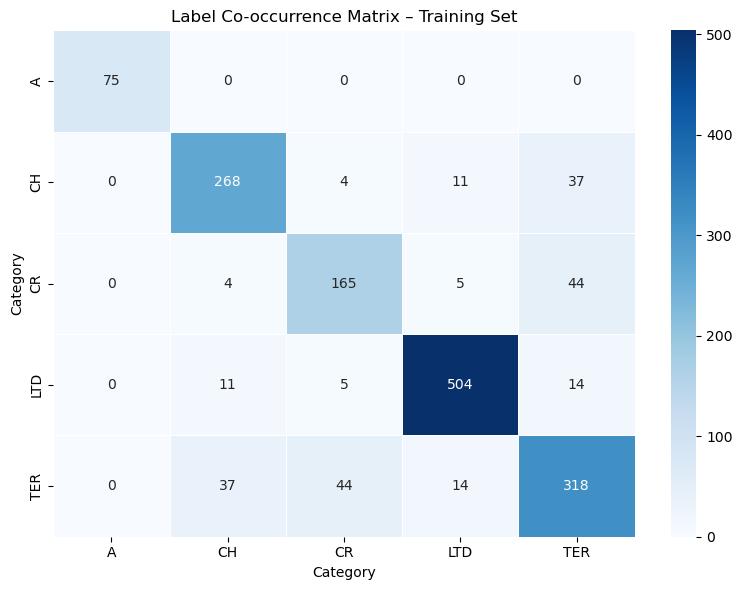

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.heatmap(
    cooccurrence_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Label Co-occurrence Matrix – Training Set")
plt.xlabel("Category")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

#### Imbalance Mitigation Strategy

To mitigate the imbalance issue, class-weighted Binary Cross-Entropy loss will be used during training. A separate positive weight will be calculated for each category as the ratio between the number of negative and positive examples. This gives greater importance to minority categories, particularly Arbitration and Content Removal, during model optimisation.

Depending on the achieved results during training, the threshold tuning strategy will also be considered.

## Task 3 - Text Encoding

### GloVe embeddings

In [31]:
from collections import Counter
from nltk.tokenize import wordpunct_tokenize
from pathlib import Path
import urllib.request
import zipfile

embeddings_dim = "50" # [50, 100, ...]

GLOVE_DIR = Path("./embeddings")
GLOVE_DIR.mkdir(exist_ok=True)

glove_zip = GLOVE_DIR / f"glove.6B.{embeddings_dim}d.zip"
glove_url = (
    "https://zenodo.org/records/4925376/files/"
    f"glove.6B.{embeddings_dim}d.zip?download=1"
)

if not glove_zip.exists():
    print(f"Downloading GloVe embeddings (For embedding dimension: {embeddings_dim})")
    urllib.request.urlretrieve(glove_url, glove_zip)

glove_file = GLOVE_DIR / f"glove.6B.{embeddings_dim}d"

if not glove_file.exists():
    print(f"Extracting GloVe embeddings (For embedding dimension: {embeddings_dim})")
    with zipfile.ZipFile(glove_zip, "r") as zip_ref:
        zip_ref.extract(f"glove.6B.{embeddings_dim}d", GLOVE_DIR)
        
        # extracted_file = GLOVE_DIR / f"glove.6B.{embeddings_dim}d"
        # extracted_file.rename(glove_file)

print("GloVe embeddings ready!")

Extracting GloVe embeddings (For embedding dimension: 50)
GloVe embeddings ready!


In [37]:
from gensim.models import KeyedVectors
from pathlib import Path

glove_embeddings = KeyedVectors.load_word2vec_format(
    str(glove_file),
    binary=True
)

print("Vocabulary size:", len(glove_embeddings))
print("Embedding dimension:", glove_embeddings.vector_size)

Vocabulary size: 400000
Embedding dimension: 50
